In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Set plotting style
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("../data/H2.csv")

leakage_cols = [
    'IsCanceled', 'ReservationStatus', 'ReservationStatusDate',
    'ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth'
]
df_cluster = df.drop(columns=[col for col in leakage_cols if col in df.columns], errors='ignore').copy()

# Feature Engineering: Combine guest counts to avoid zero-inflation in separate child/baby columns
df_cluster['TotalGuests'] = (
    df_cluster['Adults'].fillna(0) +
    df_cluster['Children'].fillna(0) +
    df_cluster['Babies'].fillna(0)
)

outlier_cols = ['LeadTime', 'StaysInWeekNights', 'StaysInWeekendNights', 'TotalGuests'] # TODO: Tested a lot, but this looks to be the best
for col in outlier_cols:
    Q1 = df_cluster[col].quantile(0.25)
    Q3 = df_cluster[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_cluster = df_cluster[(df_cluster[col] >= max(0, lower_bound)) & (df_cluster[col] <= upper_bound)]

print(f"Dataset shape after outlier removal: {df_cluster.shape}")

numeric_features = [
    'LeadTime',
    'StaysInWeekendNights',
    'StaysInWeekNights',
    'TotalGuests',
    'TotalOfSpecialRequests',
    'RequiredCarParkingSpaces'
]

categorical_features = [
    'MarketSegment',
    'CustomerType',
    'ReservedRoomType',
    'Meal',
    'DistributionChannel',
    'IsRepeatedGuest'
]

selected_features = numeric_features + categorical_features
X_cluster = df_cluster[selected_features].copy()

Dataset shape after outlier removal: (51117, 25)


In [3]:
# ==========================================
# 2. SEPARATE PIPELINE FOR NON-DUPLICATES
# ==========================================
df_unique = df.drop_duplicates().copy()

df_cluster_unique = df_unique.drop(columns=[col for col in leakage_cols if col in df_unique.columns], errors='ignore').copy()

# Feature Engineering for non-duplicates dataset
df_cluster_unique['TotalGuests'] = (
    df_cluster_unique['Adults'].fillna(0) +
    df_cluster_unique['Children'].fillna(0) +
    df_cluster_unique['Babies'].fillna(0)
)

# Outlier removal for non-duplicates dataset
for col in outlier_cols:
    Q1 = df_cluster_unique[col].quantile(0.25)
    Q3 = df_cluster_unique[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_cluster_unique = df_cluster_unique[(df_cluster_unique[col] >= max(0, lower_bound)) & (df_cluster_unique[col] <= upper_bound)]

print(f"Deduplicated Dataset shape after outlier removal: {df_cluster_unique.shape}")

X_cluster_unique = df_cluster_unique[selected_features].copy()

Deduplicated Dataset shape after outlier removal: (32295, 25)


In [4]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

clustering_preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Fit and transform feature matrix
X_cluster_transformed = clustering_preprocessor.fit_transform(X_cluster)
print(f"Transformed feature matrix shape: {X_cluster_transformed.shape}")

# Fit and transform deduplicated feature matrix
X_cluster_unique_transformed = clustering_preprocessor.fit_transform(X_cluster_unique)
print(f"Transformed feature matrix shape (Deduplicated): {X_cluster_unique_transformed.shape}")

Transformed feature matrix shape: (51117, 36)
Transformed feature matrix shape (Deduplicated): (32295, 36)


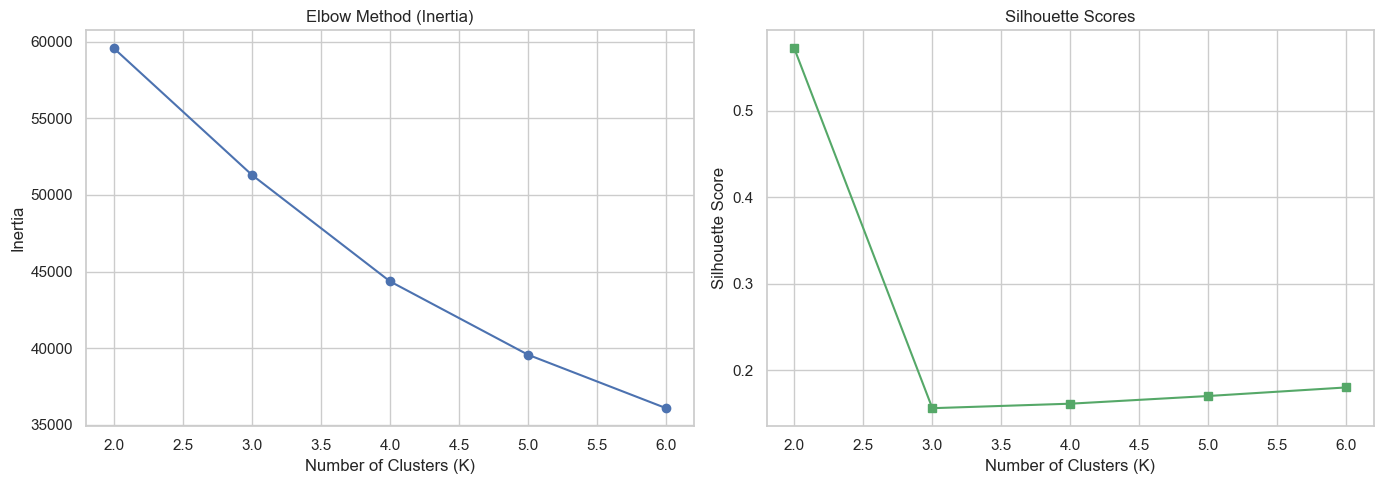

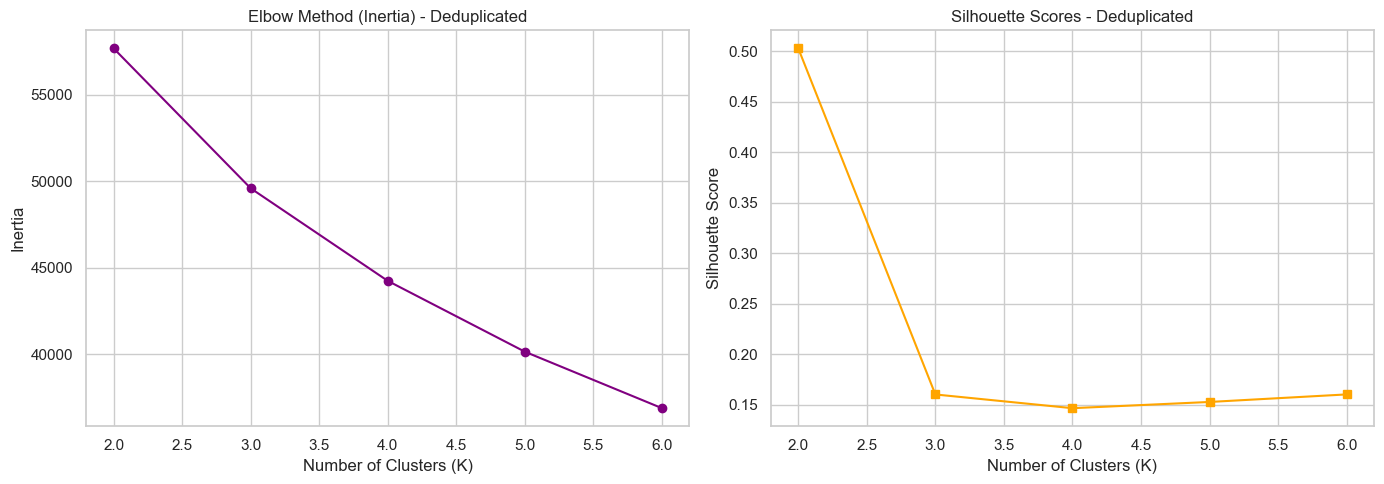

In [5]:
# Using a sample of 10,000 rows for efficient computation of metrics
sample_idx = np.random.RandomState(233).choice(
    X_cluster_transformed.shape[0], size=min(10000, X_cluster_transformed.shape[0]), replace=False
)
X_sample = X_cluster_transformed[sample_idx]

inertias = []
silhouette_scores = []
K_range = range(2, 7)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=233, n_init=10)
    labels = kmeans.fit_predict(X_sample)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_sample, labels))

# Plot evaluation curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, inertias, marker='o', linestyle='-', color='b')
axes[0].set_title('Elbow Method (Inertia)')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')

axes[1].plot(K_range, silhouette_scores, marker='s', linestyle='-', color='g')
axes[1].set_title('Silhouette Scores')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()


# Using a sample of 10,000 rows for efficient computation of metrics (Deduplicated Data)
sample_idx_unique = np.random.RandomState(233).choice(
    X_cluster_unique_transformed.shape[0], size=min(10000, X_cluster_unique_transformed.shape[0]), replace=False
)
X_sample_unique = X_cluster_unique_transformed[sample_idx_unique]

inertias_unique = []
silhouette_scores_unique = []
K_range = range(2, 7)

for k in K_range:
    kmeans_u = KMeans(n_clusters=k, random_state=233, n_init=10)
    labels_u = kmeans_u.fit_predict(X_sample_unique)
    inertias_unique.append(kmeans_u.inertia_)
    silhouette_scores_unique.append(silhouette_score(X_sample_unique, labels_u))

# Plot evaluation curves for deduplicated data
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, inertias_unique, marker='o', linestyle='-', color='purple')
axes[0].set_title('Elbow Method (Inertia) - Deduplicated')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')

axes[1].plot(K_range, silhouette_scores_unique, marker='s', linestyle='-', color='orange')
axes[1].set_title('Silhouette Scores - Deduplicated')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

In [12]:
# Choose optimal K based on the plots above
optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, random_state=233, n_init=10)
cluster_labels = kmeans_final.fit_predict(X_cluster_transformed)

# Attach cluster labels back to dataframe
df_cluster['Cluster'] = cluster_labels
print("\nCluster Distribution:")
print(df_cluster['Cluster'].value_counts())


# Choose optimal K for deduplicated data based on the plots above
optimal_k_unique = 3
kmeans_final_unique = KMeans(n_clusters=optimal_k_unique, random_state=233, n_init=10)
cluster_labels_unique = kmeans_final_unique.fit_predict(X_cluster_unique_transformed)

# Attach cluster labels back to deduplicated dataframe
df_cluster_unique['Cluster'] = cluster_labels_unique
print("\nCluster Distribution (Deduplicated):")
print(df_cluster_unique['Cluster'].value_counts())


Cluster Distribution:
Cluster
0    31840
2    18206
1     1071
Name: count, dtype: int64

Cluster Distribution (Deduplicated):
Cluster
0    18832
1    12413
2     1050
Name: count, dtype: int64


In [13]:
# Re-introduce ADR (and original cancellation data if desired) for profiling purposes only
df_cluster['ADR'] = df['ADR']
df_cluster['IsCanceled'] = df['IsCanceled']

# Group by cluster and compute mean values to interpret guest profiles
profile_numeric = numeric_features + ['ADR']
cluster_profile = df_cluster.groupby('Cluster')[profile_numeric].mean()

print("\n--- Cluster Profiling (Mean Values) ---")
display(cluster_profile)


# Re-introduce ADR and cancellation data for profiling deduplicated data using original index references
df_cluster_unique['ADR'] = df.loc[df_cluster_unique.index, 'ADR']
df_cluster_unique['IsCanceled'] = df.loc[df_cluster_unique.index, 'IsCanceled']

# Group by cluster and compute mean values for deduplicated profiles
cluster_profile_unique = df_cluster_unique.groupby('Cluster')[profile_numeric].mean()

print("\n--- Cluster Profiling (Mean Values - Deduplicated) ---")
display(cluster_profile_unique)


--- Cluster Profiling (Mean Values) ---


,LeadTime,StaysInWeekendNights,StaysInWeekNights,TotalGuests,TotalOfSpecialRequests,RequiredCarParkingSpaces,ADR
Cluster,,,,,,,
0,129.044535,0.753580,2.090609,2.0,0.061369,0.000000,96.282034
1,61.741363,0.698413,1.906629,2.0,0.937442,1.001867,115.656340
2,79.472097,0.895199,2.348511,2.0,1.372844,0.000000,108.796769



--- Cluster Profiling (Mean Values - Deduplicated) ---


,LeadTime,StaysInWeekendNights,StaysInWeekNights,TotalGuests,TotalOfSpecialRequests,RequiredCarParkingSpaces,ADR
Cluster,,,,,,,
0,35.309102,0.696846,1.761895,2.0,0.668543,0.000000,106.378461
1,133.920084,1.189640,3.073069,2.0,0.782406,0.000000,103.621233
2,59.874286,0.691429,1.917143,2.0,0.936190,1.001905,115.778790


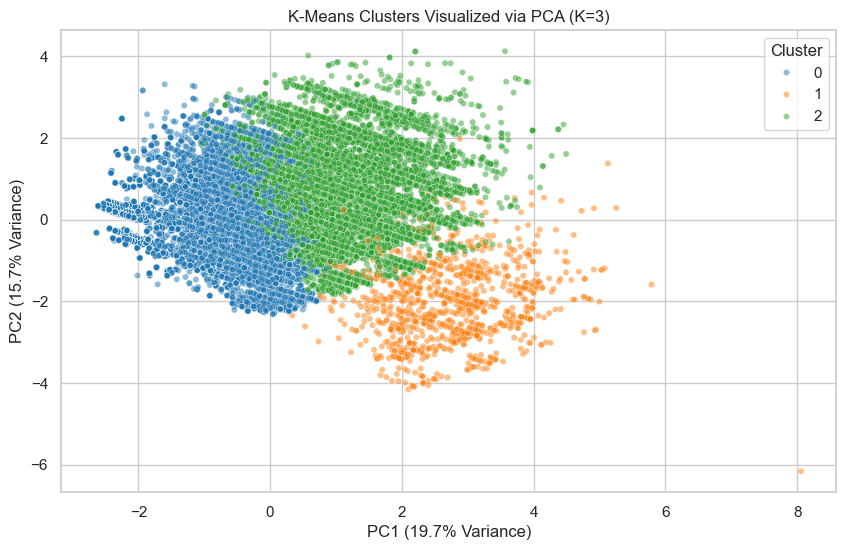

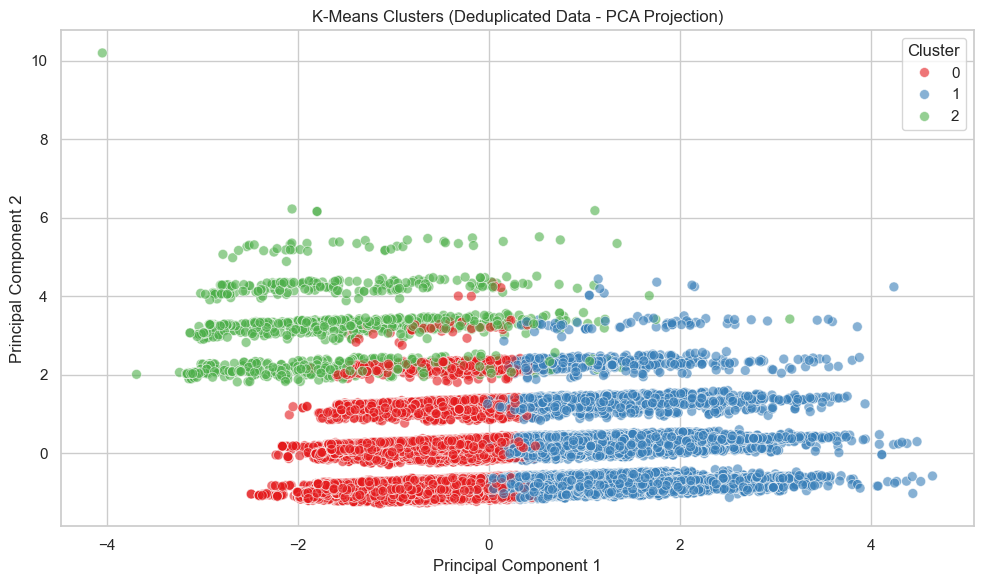

In [14]:
pca_2d = PCA(n_components=2, random_state=233)
X_pca_2d = pca_2d.fit_transform(X_cluster_transformed)

df_vis = pd.DataFrame(X_pca_2d, columns=['PC1', 'PC2'])
df_vis['Cluster'] = cluster_labels

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_vis, x='PC1', y='PC2', hue='Cluster',
    palette='tab10', alpha=0.5, s=20
)
plt.title(f'K-Means Clusters Visualized via PCA (K={optimal_k})')
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% Variance)')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% Variance)')
plt.legend(title='Cluster')
plt.show()


# Reduce the deduplicated transformed features to 2 dimensions for visualization
pca = PCA(n_components=2, random_state=233)
X_pca_unique = pca.fit_transform(X_cluster_unique_transformed)

# Create a temporary dataframe for plotting
df_pca_unique = pd.DataFrame(X_pca_unique, columns=['PC1', 'PC2'])
df_pca_unique['Cluster'] = cluster_labels_unique

# Plot the clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1', y='PC2',
    hue='Cluster',
    data=df_pca_unique,
    palette='Set1',
    alpha=0.6,
    s=50
)
plt.title('K-Means Clusters (Deduplicated Data - PCA Projection)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()